# 07 — Toronto heat-conditioned accessibility: absolute vs relative thermal impedance

## Purpose

This notebook compares two thermal walking-cost formulations for the U of T pilot.

Notebook 06 showed that the corrected Toronto thermal network is technically valid,
but almost the entire network exceeds the Sevilla-style 32°C threshold.

Therefore we compare:

### Model A — absolute threshold

\[
c_e^{abs}
=
t_e
\left[
1+\lambda\max(UTCI_e-32,0)
ight]
\]

### Model B — relative thermal contrast

\[
c_e^{rel}
=
t_e
\left[
1+\lambda\max(UTCI_e-UTCI_{ref},0)
ight]
\]

where \(UTCI_{ref}\) is the **network median UTCI**.

The relative model is exploratory. It is intended to preserve hotter-vs-cooler
street differences within a generally hot event.

This version also explicitly converts GraphML edge attributes back to numeric
values after loading, because GraphML may deserialize numeric attributes as strings.

**Kernel:** Python 3.12 - VoxCity

## 1. Imports and project paths

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import osmnx as ox
import pandas as pd

HERE = Path.cwd().resolve()

if HERE.name == "notebooks_toronto_v02":
    PROJECT_ROOT = HERE.parent
elif (HERE / "notebooks_toronto_v02").exists():
    PROJECT_ROOT = HERE
else:
    PROJECT_ROOT = Path(
        "/scratch/project_2010417/paper3/heat-conditioned-accessibility"
    )

TORONTO_INTERIM = PROJECT_ROOT / "data" / "toronto" / "interim"
TORONTO_OUTPUTS = PROJECT_ROOT / "outputs" / "toronto"

THERMAL_GRAPH_PATH = (
    TORONTO_INTERIM
    / "thermal_network"
    / "toronto_uoft_walk_thermal.graphml"
)

ACCESSIBILITY_DIR = (
    TORONTO_OUTPUTS
    / "accessibility"
)

ACCESSIBILITY_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

print("Thermal graph:", THERMAL_GRAPH_PATH)
print("Output directory:", ACCESSIBILITY_DIR)

Thermal graph: /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/interim/thermal_network/toronto_uoft_walk_thermal.graphml
Output directory: /scratch/project_2010417/paper3/heat-conditioned-accessibility/outputs/toronto/accessibility


## 2. Load the corrected thermal graph

In [2]:
if not THERMAL_GRAPH_PATH.exists():
    raise FileNotFoundError(
        f"Thermal graph not found: {THERMAL_GRAPH_PATH}"
    )

G = ox.load_graphml(
    THERMAL_GRAPH_PATH
)

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())
print("CRS:", G.graph.get("crs"))

Nodes: 3886
Edges: 10556
CRS: PROJCS["WGS 84 / UTM zone 17N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-81],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32617"]]


## 3. Restore numeric GraphML edge attributes

GraphML can reload numeric-looking values as strings.

We therefore coerce all thermal and impedance attributes back to floats before any
network statistics or shortest-path calculations are performed.

In [3]:
NUMERIC_EDGE_ATTRS = [
    "length",
    "walk_time_s",
    "utci_1500",
    "heat_excess",
    "thermal_cost_s",
    "cost_ratio",
    "utci_sample_n",
]

conversion_failures = {
    attr: 0
    for attr in NUMERIC_EDGE_ATTRS
}

for u, v, key, data in G.edges(
    keys=True,
    data=True,
):

    for attr in NUMERIC_EDGE_ATTRS:

        if attr not in data:
            continue

        try:
            data[attr] = float(
                data[attr]
            )

        except (
            TypeError,
            ValueError,
        ):

            data[attr] = np.nan
            conversion_failures[attr] += 1

print(
    "✓ Numeric edge attributes restored."
)

print(
    "Conversion failures:",
    conversion_failures,
)

✓ Numeric edge attributes restored.
Conversion failures: {'length': 0, 'walk_time_s': 0, 'utci_1500': 0, 'heat_excess': 0, 'thermal_cost_s': 0, 'cost_ratio': 0, 'utci_sample_n': 0}


## 4. Keep the largest strongly connected component

In [4]:
strong_components = sorted(
    nx.strongly_connected_components(
        G
    ),
    key=len,
    reverse=True,
)

if not strong_components:
    raise RuntimeError(
        "No strongly connected components found."
    )

G_main = (
    G.subgraph(
        strong_components[0]
    )
    .copy()
)

print(
    "Largest SCC nodes:",
    G_main.number_of_nodes(),
)

print(
    "Largest SCC edges:",
    G_main.number_of_edges(),
)

print(
    "Node retention share:",
    round(
        G_main.number_of_nodes()
        / G.number_of_nodes(),
        4,
    ),
)

Largest SCC nodes: 3886
Largest SCC edges: 10556
Node retention share: 1.0


## 5. Convert graph to GeoDataFrames and verify numeric types

In [5]:
nodes, edges = ox.graph_to_gdfs(
    G_main
)

for column in NUMERIC_EDGE_ATTRS:

    if column in edges.columns:

        edges[column] = pd.to_numeric(
            edges[column],
            errors="coerce",
        )

print(
    edges[
        [
            column
            for column in NUMERIC_EDGE_ATTRS
            if column in edges.columns
        ]
    ].dtypes
)

display(
    edges[
        [
            "length",
            "walk_time_s",
            "utci_1500",
            "heat_excess",
        ]
    ].describe()
)

length            float64
walk_time_s       float64
utci_1500         float64
heat_excess       float64
thermal_cost_s    float64
cost_ratio        float64
utci_sample_n     float64
dtype: object


,length,walk_time_s,utci_1500,heat_excess
count,10556.000000,10556.000000,10556.000000,10556.000000
mean,31.967763,22.834117,35.576699,3.578045
std,37.622891,26.873494,0.616346,0.607730
min,0.125179,0.089414,30.965675,0.000000
25%,9.293289,6.638063,35.496085,3.496085
50%,18.382359,13.130256,35.790959,3.790959
75%,41.801727,29.858377,35.935836,3.935836
max,372.304178,265.931555,36.287238,4.287238


## 6. Build the stop-query polygon

In [6]:
graph_polygon_projected = (
    edges.union_all().convex_hull
)

graph_polygon_wgs84 = (
    gpd.GeoSeries(
        [graph_polygon_projected],
        crs=edges.crs,
    )
    .to_crs(4326)
    .iloc[0]
)

print(
    "Stop-query polygon prepared."
)

Stop-query polygon prepared.


## 7. Retrieve public-transport stops from OpenStreetMap

In [7]:
tags = {
    "highway": "bus_stop",
    "public_transport": [
        "platform",
        "stop_position",
    ],
}

stops_raw = ox.features_from_polygon(
    graph_polygon_wgs84,
    tags=tags,
)

print(
    "Raw transit features:",
    len(stops_raw),
)

Raw transit features: 223


## 8. Clean stop geometries

In [8]:
stops = (
    stops_raw
    .reset_index()
    .copy()
)

stops = stops[
    stops.geometry.geom_type.isin(
        [
            "Point",
            "Polygon",
            "MultiPolygon",
        ]
    )
].copy()

stops = stops.to_crs(
    edges.crs
)

polygon_mask = (
    stops.geometry.geom_type.isin(
        [
            "Polygon",
            "MultiPolygon",
        ]
    )
)

stops.loc[
    polygon_mask,
    "geometry",
] = stops.loc[
    polygon_mask,
    "geometry",
].geometry.centroid

stops = stops.drop_duplicates(
    subset="geometry"
).copy()

print(
    "Clean stop geometries:",
    len(stops),
)

Clean stop geometries: 223


## 9. Snap stops to the thermal graph

In [9]:
stop_nodes = ox.distance.nearest_nodes(
    G_main,
    X=stops.geometry.x,
    Y=stops.geometry.y,
)

stops["node"] = stop_nodes

stop_nodes_unique = sorted(
    set(
        stop_nodes
    )
)

stop_nodes_final = [
    node
    for node in stop_nodes_unique
    if node in G_main.nodes
]

print(
    "Final unique stop nodes:",
    len(stop_nodes_final),
)

if len(stop_nodes_final) == 0:
    raise RuntimeError(
        "No transit-stop nodes remain after snapping."
    )

Final unique stop nodes: 167


## 10. Define reproducible origins

In [10]:
N_ORIGINS = 50
RANDOM_SEED = 42

rng = np.random.default_rng(
    RANDOM_SEED
)

candidate_origins = np.array(
    list(
        G_main.nodes
    )
)

n_origins = min(
    N_ORIGINS,
    len(candidate_origins),
)

origin_nodes = rng.choice(
    candidate_origins,
    size=n_origins,
    replace=False,
).tolist()

print(
    "Origin nodes:",
    len(origin_nodes),
)

Origin nodes: 50


## 11. Accessibility settings

In [11]:
BUDGET_S = 600.0

LAMBDA_VALUES = [
    0.00,
    0.01,
    0.025,
    0.05,
    0.075,
    0.10,
]

ABS_THRESHOLD_C = 32.0

UTCI_REF = float(
    pd.to_numeric(
        edges[
            "utci_1500"
        ],
        errors="coerce",
    ).median()
)

print(
    "Budget:",
    BUDGET_S,
    "s",
)

print(
    "Absolute threshold:",
    ABS_THRESHOLD_C,
    "°C",
)

print(
    "Median network UTCI reference:",
    round(
        UTCI_REF,
        3,
    ),
    "°C",
)

Budget: 600.0 s
Absolute threshold: 32.0 °C
Median network UTCI reference: 35.791 °C


## 12. Add absolute and relative impedance weights

In [12]:
for u, v, key, data in G_main.edges(
    keys=True,
    data=True,
):

    walk_time = float(
        data[
            "walk_time_s"
        ]
    )

    utci_value = float(
        data[
            "utci_1500"
        ]
    )

    abs_excess = max(
        utci_value
        - ABS_THRESHOLD_C,
        0.0,
    )

    rel_excess = max(
        utci_value
        - UTCI_REF,
        0.0,
    )

    data[
        "abs_excess"
    ] = abs_excess

    data[
        "rel_excess"
    ] = rel_excess

    for lam in LAMBDA_VALUES:

        data[
            f"abs_{lam}"
        ] = (
            walk_time
            * (
                1.0
                + lam
                * abs_excess
            )
        )

        data[
            f"rel_{lam}"
        ] = (
            walk_time
            * (
                1.0
                + lam
                * rel_excess
            )
        )

## 13. Inspect the two penalty fields

In [13]:
nodes, edges = ox.graph_to_gdfs(
    G_main
)

for column in [
    "abs_excess",
    "rel_excess",
]:

    edges[column] = pd.to_numeric(
        edges[column],
        errors="coerce",
    )

display(
    edges[
        [
            "abs_excess",
            "rel_excess",
        ]
    ].describe()
)

print(
    "Share edges with absolute penalty:",
    float(
        (
            edges[
                "abs_excess"
            ] > 0
        ).mean()
    ),
)

print(
    "Share edges with relative penalty:",
    float(
        (
            edges[
                "rel_excess"
            ] > 0
        ).mean()
    ),
)

,abs_excess,rel_excess
count,10556.000000,10556.000000
mean,3.578045,0.069254
std,0.607730,0.086556
min,0.000000,0.000000
25%,3.496085,0.000000
50%,3.790959,0.000040
75%,3.935836,0.144876
max,4.287238,0.496279


Share edges with absolute penalty: 0.9975369458128078
Share edges with relative penalty: 0.5


## 14. Accessibility helper

In [14]:
def reachable_stop_count(
    graph,
    origin,
    stop_nodes,
    weight,
    cutoff,
):

    lengths = (
        nx.single_source_dijkstra_path_length(
            graph,
            origin,
            cutoff=cutoff,
            weight=weight,
        )
    )

    reachable = [
        stop
        for stop in stop_nodes
        if stop in lengths
        and lengths[stop] <= cutoff
    ]

    return (
        len(reachable),
        set(reachable),
    )

## 15. Compute accessibility for all origins and λ values

In [15]:
results = []
reachable_sets = {}

for origin in origin_nodes:

    normal_count, normal_set = (
        reachable_stop_count(
            G_main,
            origin,
            stop_nodes_final,
            weight="walk_time_s",
            cutoff=BUDGET_S,
        )
    )

    results.append(
        {
            "origin": origin,
            "model": "normal",
            "lambda": 0.0,
            "reachable_stops": normal_count,
        }
    )

    reachable_sets[
        (
            origin,
            "normal",
            0.0,
        )
    ] = normal_set

    for lam in LAMBDA_VALUES:

        if lam == 0:
            continue

        abs_count, abs_set = (
            reachable_stop_count(
                G_main,
                origin,
                stop_nodes_final,
                weight=f"abs_{lam}",
                cutoff=BUDGET_S,
            )
        )

        results.append(
            {
                "origin": origin,
                "model": "absolute",
                "lambda": lam,
                "reachable_stops": abs_count,
            }
        )

        reachable_sets[
            (
                origin,
                "absolute",
                lam,
            )
        ] = abs_set

        rel_count, rel_set = (
            reachable_stop_count(
                G_main,
                origin,
                stop_nodes_final,
                weight=f"rel_{lam}",
                cutoff=BUDGET_S,
            )
        )

        results.append(
            {
                "origin": origin,
                "model": "relative",
                "lambda": lam,
                "reachable_stops": rel_count,
            }
        )

        reachable_sets[
            (
                origin,
                "relative",
                lam,
            )
        ] = rel_set

results_df = pd.DataFrame(
    results
)

display(
    results_df.head()
)

,origin,model,lambda,reachable_stops
0,8711032240,normal,0.000,47
1,8711032240,absolute,0.010,45
2,8711032240,relative,0.010,47
3,8711032240,absolute,0.025,38
4,8711032240,relative,0.025,47


## 16. Build sensitivity summaries

In [16]:
normal_access = (
    results_df[
        results_df[
            "model"
        ] == "normal"
    ]
    .set_index(
        "origin"
    )[
        "reachable_stops"
    ]
)

sensitivity_rows = []

for model in [
    "absolute",
    "relative",
]:

    for lam in [
        value
        for value in LAMBDA_VALUES
        if value > 0
    ]:

        current = (
            results_df[
                (
                    results_df[
                        "model"
                    ] == model
                )
                &
                (
                    results_df[
                        "lambda"
                    ] == lam
                )
            ]
            .set_index(
                "origin"
            )[
                "reachable_stops"
            ]
        )

        aligned = pd.concat(
            [
                normal_access.rename(
                    "normal"
                ),
                current.rename(
                    "current"
                ),
            ],
            axis=1,
        ).dropna()

        loss_pct = np.where(
            aligned[
                "normal"
            ] > 0,
            (
                aligned[
                    "normal"
                ]
                - aligned[
                    "current"
                ]
            )
            / aligned[
                "normal"
            ]
            * 100,
            np.nan,
        )

        sensitivity_rows.append(
            {
                "model": model,
                "lambda": lam,
                "mean_reachable": float(
                    aligned[
                        "current"
                    ].mean()
                ),
                "median_reachable": float(
                    aligned[
                        "current"
                    ].median()
                ),
                "std_reachable": float(
                    aligned[
                        "current"
                    ].std()
                ),
                "min_reachable": int(
                    aligned[
                        "current"
                    ].min()
                ),
                "max_reachable": int(
                    aligned[
                        "current"
                    ].max()
                ),
                "mean_loss_pct": float(
                    np.nanmean(
                        loss_pct
                    )
                ),
            }
        )

sensitivity_df = pd.DataFrame(
    sensitivity_rows
)

display(
    sensitivity_df
)

,model,lambda,mean_reachable,median_reachable,std_reachable,min_reachable,max_reachable,mean_loss_pct
0,absolute,0.010,39.56,39.5,13.246732,8,62,5.423702
1,absolute,0.025,35.98,35.5,12.110865,5,57,14.142818
2,absolute,0.050,30.96,31.5,10.044716,4,51,25.616491
3,absolute,0.075,27.34,28.5,9.349473,2,46,34.609082
4,absolute,0.100,24.22,24.0,8.415947,2,45,41.663420
5,relative,0.010,41.82,42.5,14.232314,9,65,0.227273
6,relative,0.025,41.82,42.5,14.232314,9,65,0.227273
7,relative,0.050,41.82,42.5,14.232314,9,65,0.227273
8,relative,0.075,41.72,42.5,14.254308,9,65,0.511532
9,relative,0.100,41.64,42.5,14.255339,8,65,0.848302


## 17. Plot sensitivity curves

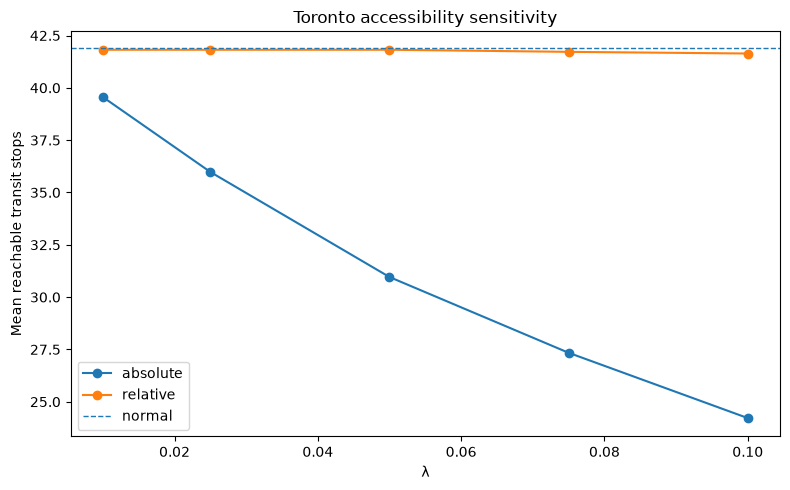

In [17]:
fig, ax = plt.subplots(
    figsize=(8, 5)
)

for model in [
    "absolute",
    "relative",
]:

    model_df = (
        sensitivity_df[
            sensitivity_df[
                "model"
            ] == model
        ]
    )

    ax.plot(
        model_df["lambda"],
        model_df["mean_reachable"],
        marker="o",
        label=model,
    )

ax.axhline(
    normal_access.mean(),
    linestyle="--",
    linewidth=1,
    label="normal",
)

ax.set_xlabel(
    "λ"
)

ax.set_ylabel(
    "Mean reachable transit stops"
)

ax.set_title(
    "Toronto accessibility sensitivity"
)

ax.legend()

plt.tight_layout()
plt.show()

## 18. Compare λ = 0.05 directly

In [18]:
REFERENCE_LAMBDA = 0.05

absolute_ref = (
    results_df[
        (
            results_df[
                "model"
            ] == "absolute"
        )
        &
        (
            results_df[
                "lambda"
            ] == REFERENCE_LAMBDA
        )
    ]
    .set_index(
        "origin"
    )[
        "reachable_stops"
    ]
    .rename(
        "absolute_access"
    )
)

relative_ref = (
    results_df[
        (
            results_df[
                "model"
            ] == "relative"
        )
        &
        (
            results_df[
                "lambda"
            ] == REFERENCE_LAMBDA
        )
    ]
    .set_index(
        "origin"
    )[
        "reachable_stops"
    ]
    .rename(
        "relative_access"
    )
)

comparison = pd.concat(
    [
        normal_access.rename(
            "normal_access"
        ),
        absolute_ref,
        relative_ref,
    ],
    axis=1,
).dropna()

comparison[
    "absolute_loss_pct"
] = np.where(
    comparison[
        "normal_access"
    ] > 0,
    (
        comparison[
            "normal_access"
        ]
        - comparison[
            "absolute_access"
        ]
    )
    / comparison[
        "normal_access"
    ]
    * 100,
    np.nan,
)

comparison[
    "relative_loss_pct"
] = np.where(
    comparison[
        "normal_access"
    ] > 0,
    (
        comparison[
            "normal_access"
        ]
        - comparison[
            "relative_access"
        ]
    )
    / comparison[
        "normal_access"
    ]
    * 100,
    np.nan,
)

display(
    comparison.describe()
)

,normal_access,absolute_access,relative_access,absolute_loss_pct,relative_loss_pct
count,50.000000,50.000000,50.000000,50.000000,50.000000
mean,41.880000,30.960000,41.820000,25.616491,0.227273
std,14.166128,10.044716,14.232314,9.135791,0.918320
min,9.000000,4.000000,9.000000,5.555556,0.000000
25%,31.000000,23.250000,31.000000,19.473684,0.000000
50%,42.500000,31.500000,42.500000,25.806452,0.000000
75%,53.750000,37.500000,53.750000,30.715812,0.000000
max,65.000000,51.000000,65.000000,55.555556,4.166667


## 19. Reference-case summary

In [19]:
print(
    "Normal mean reachable stops:",
    comparison[
        "normal_access"
    ].mean(),
)

print(
    "Absolute λ=.05 mean reachable:",
    comparison[
        "absolute_access"
    ].mean(),
)

print(
    "Relative λ=.05 mean reachable:",
    comparison[
        "relative_access"
    ].mean(),
)

print()

print(
    "Absolute mean loss (%):",
    comparison[
        "absolute_loss_pct"
    ].mean(),
)

print(
    "Relative mean loss (%):",
    comparison[
        "relative_loss_pct"
    ].mean(),
)

Normal mean reachable stops: 41.88
Absolute λ=.05 mean reachable: 30.96
Relative λ=.05 mean reachable: 41.82

Absolute mean loss (%): 25.61649118717296
Relative mean loss (%): 0.22727272727272727


## 20. Attach origin geometries

In [20]:
origin_gdf = (
    nodes.loc[
        comparison.index
    ]
    .copy()
)

origin_results_gdf = (
    origin_gdf.join(
        comparison
    )
)

print(
    "Origin records:",
    len(
        origin_results_gdf
    ),
)

Origin records: 50


## 21. Map normal accessibility

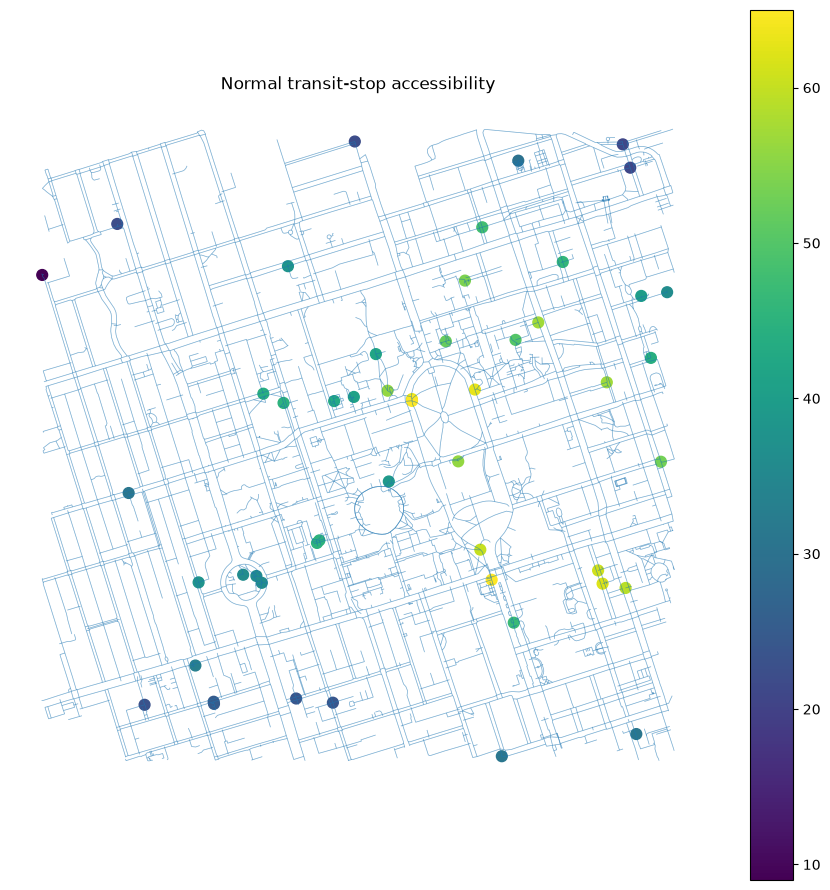

In [21]:
fig, ax = plt.subplots(
    figsize=(9, 9)
)

edges.plot(
    ax=ax,
    linewidth=0.5,
    alpha=0.35,
)

origin_results_gdf.plot(
    ax=ax,
    column="normal_access",
    markersize=60,
    legend=True,
)

ax.set_title(
    "Normal transit-stop accessibility"
)

ax.set_axis_off()

plt.tight_layout()
plt.show()

## 22. Map absolute-threshold accessibility loss

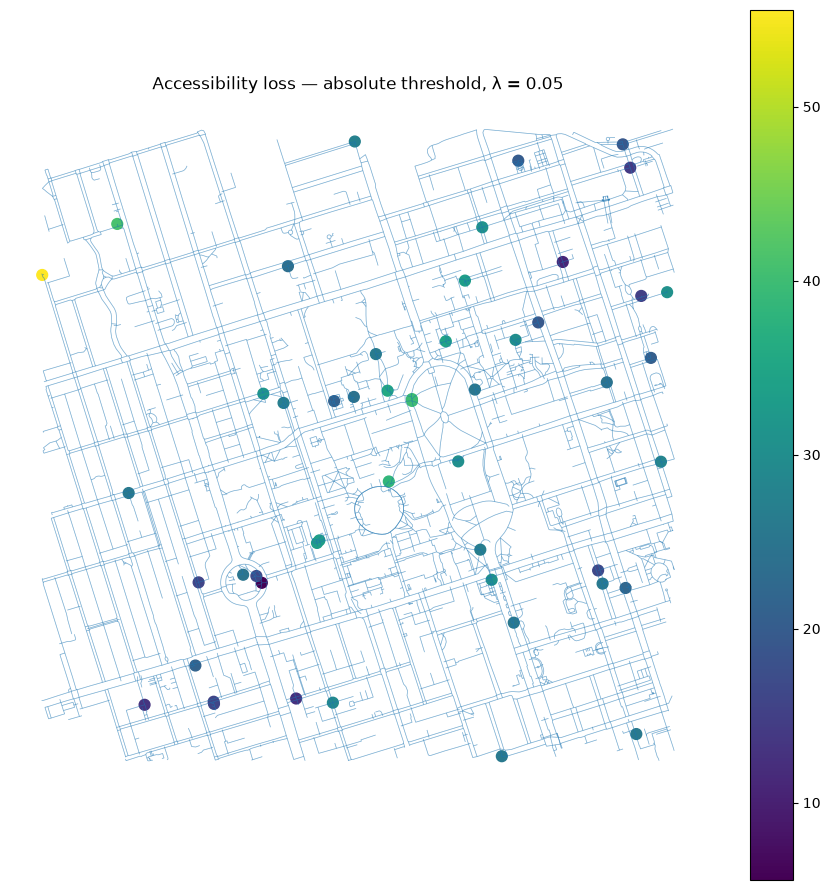

In [22]:
fig, ax = plt.subplots(
    figsize=(9, 9)
)

edges.plot(
    ax=ax,
    linewidth=0.5,
    alpha=0.35,
)

origin_results_gdf.plot(
    ax=ax,
    column="absolute_loss_pct",
    markersize=60,
    legend=True,
)

ax.set_title(
    "Accessibility loss — absolute threshold, λ = 0.05"
)

ax.set_axis_off()

plt.tight_layout()
plt.show()

## 23. Map relative-contrast accessibility loss

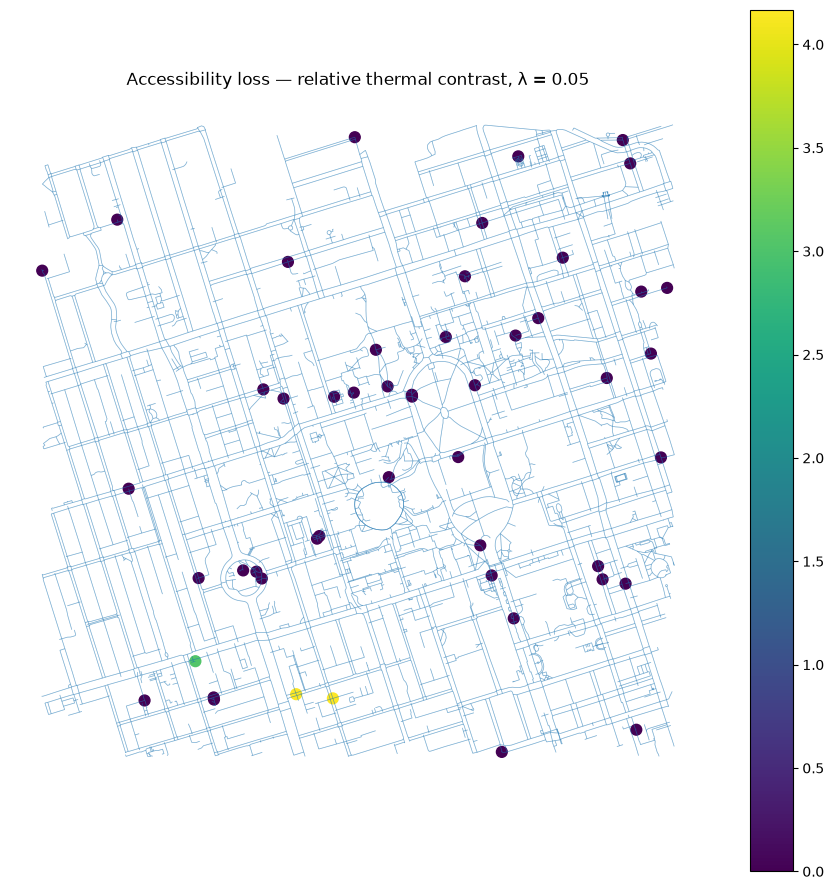

In [23]:
fig, ax = plt.subplots(
    figsize=(9, 9)
)

edges.plot(
    ax=ax,
    linewidth=0.5,
    alpha=0.35,
)

origin_results_gdf.plot(
    ax=ax,
    column="relative_loss_pct",
    markersize=60,
    legend=True,
)

ax.set_title(
    "Accessibility loss — relative thermal contrast, λ = 0.05"
)

ax.set_axis_off()

plt.tight_layout()
plt.show()

## 24. Compare spatial variation in origin-level losses

In [24]:
variation_summary = pd.DataFrame(
    {
        "metric": [
            "mean loss",
            "std loss",
            "median loss",
            "minimum loss",
            "maximum loss",
        ],
        "absolute": [
            comparison[
                "absolute_loss_pct"
            ].mean(),
            comparison[
                "absolute_loss_pct"
            ].std(),
            comparison[
                "absolute_loss_pct"
            ].median(),
            comparison[
                "absolute_loss_pct"
            ].min(),
            comparison[
                "absolute_loss_pct"
            ].max(),
        ],
        "relative": [
            comparison[
                "relative_loss_pct"
            ].mean(),
            comparison[
                "relative_loss_pct"
            ].std(),
            comparison[
                "relative_loss_pct"
            ].median(),
            comparison[
                "relative_loss_pct"
            ].min(),
            comparison[
                "relative_loss_pct"
            ].max(),
        ],
    }
)

display(
    variation_summary
)

,metric,absolute,relative
0,mean loss,25.616491,0.227273
1,std loss,9.135791,0.918320
2,median loss,25.806452,0.000000
3,minimum loss,5.555556,0.000000
4,maximum loss,55.555556,4.166667


## 25. Lost origin-stop opportunities

In [25]:
lost_rows = []

for origin in comparison.index:

    normal_set = reachable_sets[
        (
            origin,
            "normal",
            0.0,
        )
    ]

    for model in [
        "absolute",
        "relative",
    ]:

        thermal_set = reachable_sets[
            (
                origin,
                model,
                REFERENCE_LAMBDA,
            )
        ]

        lost_set = (
            normal_set
            - thermal_set
        )

        for stop_node in lost_set:

            lost_rows.append(
                {
                    "origin": origin,
                    "model": model,
                    "stop_node": stop_node,
                }
            )

lost_pairs_df = pd.DataFrame(
    lost_rows
)

if lost_pairs_df.empty:

    print(
        "No lost opportunities."
    )

else:

    display(
        lost_pairs_df.groupby(
            "model"
        ).agg(
            lost_origin_stop_pairs=(
                "stop_node",
                "size",
            ),
            unique_lost_stops=(
                "stop_node",
                "nunique",
            ),
        )
    )

,lost_origin_stop_pairs,unique_lost_stops
model,,
absolute,546,157
relative,3,3


## 26. Save outputs

In [26]:
sensitivity_path = (
    ACCESSIBILITY_DIR
    / "toronto_accessibility_model_comparison.csv"
)

origin_csv_path = (
    ACCESSIBILITY_DIR
    / "toronto_origin_accessibility_absolute_vs_relative_lambda_005.csv"
)

origin_gpkg_path = (
    ACCESSIBILITY_DIR
    / "toronto_origin_accessibility_absolute_vs_relative_lambda_005.gpkg"
)

lost_pairs_path = (
    ACCESSIBILITY_DIR
    / "toronto_lost_origin_stop_pairs_model_comparison_lambda_005.csv"
)

sensitivity_df.to_csv(
    sensitivity_path,
    index=False,
)

comparison.reset_index().to_csv(
    origin_csv_path,
    index=False,
)

origin_results_gdf.to_file(
    origin_gpkg_path,
    driver="GPKG",
)

lost_pairs_df.to_csv(
    lost_pairs_path,
    index=False,
)

print("Saved:")
print("-", sensitivity_path)
print("-", origin_csv_path)
print("-", origin_gpkg_path)
print("-", lost_pairs_path)

Saved:
- /scratch/project_2010417/paper3/heat-conditioned-accessibility/outputs/toronto/accessibility/toronto_accessibility_model_comparison.csv
- /scratch/project_2010417/paper3/heat-conditioned-accessibility/outputs/toronto/accessibility/toronto_origin_accessibility_absolute_vs_relative_lambda_005.csv
- /scratch/project_2010417/paper3/heat-conditioned-accessibility/outputs/toronto/accessibility/toronto_origin_accessibility_absolute_vs_relative_lambda_005.gpkg
- /scratch/project_2010417/paper3/heat-conditioned-accessibility/outputs/toronto/accessibility/toronto_lost_origin_stop_pairs_model_comparison_lambda_005.csv


## 27. Final comparison summary

In [27]:
print(
    "Origins:",
    len(
        comparison
    ),
)

print(
    "Transit-stop nodes:",
    len(
        stop_nodes_final
    ),
)

print(
    "Median network UTCI reference:",
    round(
        UTCI_REF,
        3,
    ),
    "°C",
)

print()

print(
    "Normal mean reachable stops:",
    round(
        float(
            comparison[
                "normal_access"
            ].mean()
        ),
        3,
    ),
)

print(
    "Absolute λ=.05 mean reachable:",
    round(
        float(
            comparison[
                "absolute_access"
            ].mean()
        ),
        3,
    ),
)

print(
    "Relative λ=.05 mean reachable:",
    round(
        float(
            comparison[
                "relative_access"
            ].mean()
        ),
        3,
    ),
)

print()

print(
    "Absolute mean accessibility loss (%):",
    round(
        float(
            comparison[
                "absolute_loss_pct"
            ].mean()
        ),
        3,
    ),
)

print(
    "Relative mean accessibility loss (%):",
    round(
        float(
            comparison[
                "relative_loss_pct"
            ].mean()
        ),
        3,
    ),
)

print()

print(
    "Absolute loss SD:",
    round(
        float(
            comparison[
                "absolute_loss_pct"
            ].std()
        ),
        3,
    ),
)

print(
    "Relative loss SD:",
    round(
        float(
            comparison[
                "relative_loss_pct"
            ].std()
        ),
        3,
    ),
)

Origins: 50
Transit-stop nodes: 167
Median network UTCI reference: 35.791 °C

Normal mean reachable stops: 41.88
Absolute λ=.05 mean reachable: 30.96
Relative λ=.05 mean reachable: 41.82

Absolute mean accessibility loss (%): 25.616
Relative mean accessibility loss (%): 0.227

Absolute loss SD: 9.136
Relative loss SD: 0.918


## Interpretation and next step

The absolute model preserves direct comparability with Sevilla.

The relative model is exploratory and asks whether hotter streets within the same
Toronto event generate a more spatially differentiated accessibility response.

Neither λ nor the median-reference formulation should yet be interpreted as
behaviorally calibrated.

Continue to:

**`08_toronto_spatial_diagnostics.ipynb`**